In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Scikit-learn:", sklearn.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Training device:", device)

NumPy: 2.1.3
Pandas: 2.2.3
PyTorch: 2.11.0+cpu
Scikit-learn: 1.6.1
Training device: cpu


In [4]:
DATA_DIR = Path("/content")
ZIP_PATH = DATA_DIR / "har_dataset.zip"
EXTRACT_DIR = DATA_DIR / "har_data"

URL = (
    "https://archive.ics.uci.edu/static/public/"
    "240/human+activity+recognition+using+smartphones.zip"
)

if not (EXTRACT_DIR / "UCI HAR Dataset").exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(URL, ZIP_PATH)

    print("Extracting main dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    # The main zip contains another zip called 'UCI HAR Dataset.zip' inside EXTRACT_DIR
    inner_zip = EXTRACT_DIR / "UCI HAR Dataset.zip"
    if inner_zip.exists():
        print("Extracting inner dataset (UCI HAR Dataset.zip)...")
        with zipfile.ZipFile(inner_zip, "r") as zip_ref:
            zip_ref.extractall(EXTRACT_DIR)

print("Dataset directory:", EXTRACT_DIR)
print("Dataset downloaded and extracted completely.")

Extracting main dataset...
Extracting inner dataset (UCI HAR Dataset.zip)...
Dataset directory: /content/har_data
Dataset downloaded and extracted completely.


In [5]:
import os

# Let's inspect the directory structure to see where the files are
print("Contents of EXTRACT_DIR:", os.listdir(EXTRACT_DIR))

# We will adjust ROOT based on what is found in EXTRACT_DIR
possible_root = EXTRACT_DIR / "UCI HAR Dataset"
if not possible_root.exists():
    # Perhaps the inner zip extracted to a nested location, let's find it dynamically
    candidates = list(EXTRACT_DIR.glob("**/activity_labels.txt"))
    if candidates:
        ROOT = candidates[0].parent
    else:
        ROOT = EXTRACT_DIR
else:
    ROOT = possible_root

TRAIN_DIR = ROOT / "train"
TEST_DIR = ROOT / "test"

print("Resolved ROOT:", ROOT)
assert ROOT.exists(), f"Dataset folder was not found at {ROOT}."
assert TRAIN_DIR.exists(), f"Training folder was not found at {TRAIN_DIR}."
assert TEST_DIR.exists(), f"Test folder was not found at {TEST_DIR}."

activity_table = pd.read_csv(
    ROOT / "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity"]
)

activity_table["activity_id"] = (
    activity_table["activity_id"].astype(int)
)

print(activity_table.to_string(index=False))

Contents of EXTRACT_DIR: ['__MACOSX', 'UCI HAR Dataset.names', 'UCI HAR Dataset', 'UCI HAR Dataset.zip']
Resolved ROOT: /content/har_data/UCI HAR Dataset
 activity_id           activity
           1            WALKING
           2   WALKING_UPSTAIRS
           3 WALKING_DOWNSTAIRS
           4            SITTING
           5           STANDING
           6             LAYING


In [6]:
SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z"
]

signal_dir = TRAIN_DIR / "Inertial Signals"

for signal in SIGNALS:
    path = signal_dir / f"{signal}_train.txt"
    assert path.exists(), f"Missing file: {path}"

print(f"Verified {len(SIGNALS)} sensor channels.")

sample = pd.read_csv(
    signal_dir / "body_acc_x_train.txt",
    sep=r"\s+",
    header=None
)

print("Sample sensor data shape:", sample.shape)
print(sample.iloc[:5, :8])

Verified 9 sensor channels.
Sample sensor data shape: (7352, 128)
          0         1         2         3         4         5         6  \
0  0.000181  0.010139  0.009276  0.005066  0.010810  0.004045  0.004757   
1  0.001094  0.004550  0.002879  0.002247  0.003305  0.002416  0.001619   
2  0.003531  0.002285 -0.000420 -0.003738 -0.006706 -0.003148  0.000733   
3 -0.001772 -0.001311  0.000388  0.000408 -0.000355  0.000998  0.001109   
4  0.000087 -0.000272  0.001022  0.003126  0.002284  0.000885  0.001933   

          7  
0  0.006214  
1  0.000981  
2  0.000668  
3 -0.003149  
4  0.002270  


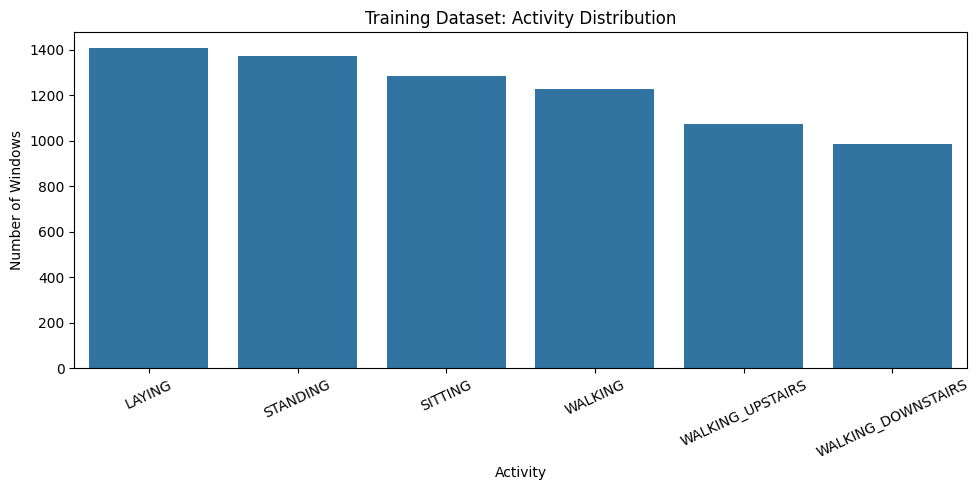

In [8]:
# Load the training labels first to fix the NameError
y_train = pd.read_csv(TRAIN_DIR / "y_train.txt", header=None)[0]

label_names = dict(
    zip(activity_table["activity_id"], activity_table["activity"])
)

counts = y_train.map(label_names).value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Training Dataset: Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Windows")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z"
]

def load_sensor_data(split):
    """Load sensor data as (samples, channels, time_steps)."""
    folder = ROOT / split / "Inertial Signals"
    signal_arrays = []

    for signal in SIGNALS:
        file_path = folder / f"{signal}_{split}.txt"
        values = pd.read_csv(
            file_path, sep=r"\s+", header=None
        ).to_numpy(dtype=np.float32)

        signal_arrays.append(values)

    # Each channel initially has shape (samples, 128).
    # Stack channels along axis 1.
    return np.stack(signal_arrays, axis=1)


X_train = load_sensor_data("train")
X_test = load_sensor_data("test")

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

X_train: (7352, 9, 128)
X_test:  (2947, 9, 128)


In [10]:
# Reload labels to ensure they match the sensor arrays.
y_train_raw = pd.read_csv(
    TRAIN_DIR / "y_train.txt", header=None
).iloc[:, 0].to_numpy(dtype=np.int64)

y_test_raw = pd.read_csv(
    TEST_DIR / "y_test.txt", header=None
).iloc[:, 0].to_numpy(dtype=np.int64)

# Convert labels 1–6 into 0–5.
y_train = y_train_raw - 1
y_test = y_test_raw - 1

CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print("Training labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))
print("Class count:", len(CLASS_NAMES))

Training labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]
Class count: 6


In [11]:
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

print("Training NaN values:", np.isnan(X_train).sum())
print("Test NaN values:", np.isnan(X_test).sum())

print("Training infinite values:", np.isinf(X_train).sum())
print("Test infinite values:", np.isinf(X_test).sum())

assert X_train.shape == (7352, 9, 128)
assert X_test.shape == (2947, 9, 128)

assert y_train.shape == (7352,)
assert y_test.shape == (2947,)

assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

assert set(np.unique(y_train)) == set(range(6))
assert set(np.unique(y_test)) == set(range(6))

print("\nAll validation checks passed!")

Training shape: (7352, 9, 128)
Test shape: (2947, 9, 128)
Training labels: (7352,)
Test labels: (2947,)
Training NaN values: 0
Test NaN values: 0
Training infinite values: 0
Test infinite values: 0

All validation checks passed!


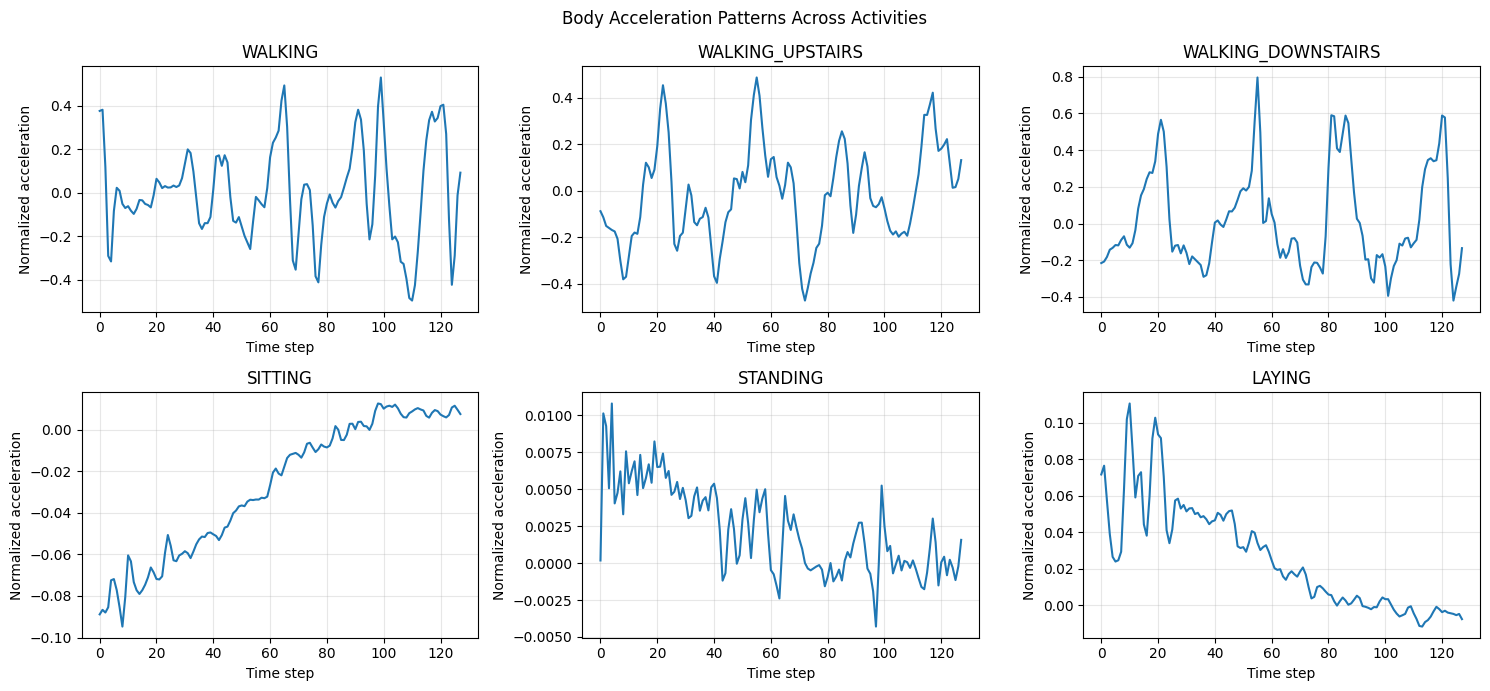

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()

for class_id, ax in enumerate(axes):
    # Find the first training example of this activity.
    sample_idx = np.where(y_train == class_id)[0][0]

    # Channel 0 = body_acc_x; 128 time steps.
    signal = X_train[sample_idx, 0, :]

    ax.plot(signal)
    ax.set_title(CLASS_NAMES[class_id])
    ax.set_xlabel("Time step")
    ax.set_ylabel("Normalized acceleration")
    ax.grid(True, alpha=0.3)

plt.suptitle("Body Acceleration Patterns Across Activities")
plt.tight_layout()
plt.show()

In [13]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert NumPy arrays into PyTorch tensors.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Group each sensor window with its correct label.
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

# Shuffle training windows, but keep test windows in a fixed order.
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Training batches: 115
Test batches: 47


In [14]:
X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)
print("Input data type:", X_batch.dtype)
print("Label data type:", y_batch.dtype)
print("Labels in batch:", torch.unique(y_batch).tolist())

assert X_batch.shape == (64, 9, 128)
assert y_batch.shape == (64,)
assert X_batch.dtype == torch.float32
assert y_batch.dtype == torch.long

print("\nPhase 2 verification successful!")

Input batch shape: torch.Size([64, 9, 128])
Label batch shape: torch.Size([64])
Input data type: torch.float32
Label data type: torch.int64
Labels in batch: [0, 1, 2, 3, 4, 5]

Phase 2 verification successful!


In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class HAR_CNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        # First convolutional block
        self.conv1 = nn.Conv1d(
            in_channels=9,
            out_channels=32,
            kernel_size=7,
            padding=3
        )
        self.pool1 = nn.MaxPool1d(kernel_size=2)

        # Second convolutional block
        self.conv2 = nn.Conv1d(
            in_channels=32,
            out_channels=64,
            kernel_size=5,
            padding=2
        )
        self.pool2 = nn.MaxPool1d(kernel_size=2)

        # Summarize each feature channel
        self.global_pool = nn.AdaptiveAvgPool1d(1)

        # Classification head
        self.dropout = nn.Dropout(p=0.3)
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool1(x)

        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)

        x = self.dropout(x)
        x = self.fc(x)

        return x


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HAR_CNN(num_classes=6).to(device)

print(model)

HAR_CNN(
  (conv1): Conv1d(9, 32, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)


In [16]:
# Use the first batch from Phase 2.
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

model.eval()

with torch.no_grad():
    logits = model(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", logits.shape)
print("Device:", device)

assert logits.shape == (64, 6)
assert torch.isfinite(logits).all()

print("Forward-pass verification successful!")

Input shape: torch.Size([64, 9, 128])
Output shape: torch.Size([64, 6])
Device: cpu
Forward-pass verification successful!


In [17]:
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 12,742


In [18]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


In [19]:
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import TensorDataset, DataLoader

# Each row identifies the participant who generated a window.
subjects = pd.read_csv(
    TRAIN_DIR / "subject_train.txt",
    header=None
).iloc[:, 0].to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=subjects)
)

train_subjects = set(subjects[train_idx])
val_subjects = set(subjects[val_idx])

assert train_subjects.isdisjoint(val_subjects)

X_fit = torch.tensor(X_train[train_idx], dtype=torch.float32)
y_fit = torch.tensor(y_train[train_idx], dtype=torch.long)

X_val = torch.tensor(X_train[val_idx], dtype=torch.float32)
y_val = torch.tensor(y_train[val_idx], dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(X_fit, y_fit),
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=128,
    shuffle=False
)

print("Training windows:", len(train_idx))
print("Validation windows:", len(val_idx))
print("Training participants:", len(train_subjects))
print("Validation participants:", len(val_subjects))
print("Participant overlap:", train_subjects & val_subjects)

Training windows: 5879
Validation windows: 1473
Training participants: 17
Validation participants: 4
Participant overlap: set()


In [20]:
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

def run_train_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Forward pass.
        logits = model(xb)
        loss = criterion(logits, yb)

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        optimizer.step()

        batch_size = yb.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += batch_size

    return total_loss / total, correct / total


def run_evaluation(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient calculations during evaluation.
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            batch_size = yb.size(0)
            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += batch_size

    return total_loss / total, correct / total

In [21]:
# Reset the model to a fresh initialization for this experiment.
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = HAR_CNN(num_classes=6).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 15
PATIENCE = 4

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    train_loss, train_acc = run_train_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = run_evaluation(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.4f}"
    )

    # Save the best model based on validation loss.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_state = {
            name: param.detach().cpu().clone()
            for name, param in model.state_dict().items()
        }

        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation loss stopped improving.")
        break

assert best_state is not None

model.load_state_dict(best_state)
model.to(device)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch 01/15 | Train loss: 1.1580 | Train accuracy: 0.5567 | Val loss: 0.5905 | Val accuracy: 0.7468
Epoch 02/15 | Train loss: 0.5082 | Train accuracy: 0.8025 | Val loss: 0.3073 | Val accuracy: 0.9260
Epoch 03/15 | Train loss: 0.3495 | Train accuracy: 0.8716 | Val loss: 0.2111 | Val accuracy: 0.9552
Epoch 04/15 | Train loss: 0.2638 | Train accuracy: 0.9083 | Val loss: 0.1749 | Val accuracy: 0.9504
Epoch 05/15 | Train loss: 0.2130 | Train accuracy: 0.9206 | Val loss: 0.1513 | Val accuracy: 0.9579
Epoch 06/15 | Train loss: 0.1936 | Train accuracy: 0.9258 | Val loss: 0.1392 | Val accuracy: 0.9606
Epoch 07/15 | Train loss: 0.1680 | Train accuracy: 0.9376 | Val loss: 0.1302 | Val accuracy: 0.9484
Epoch 08/15 | Train loss: 0.1620 | Train accuracy: 0.9355 | Val loss: 0.1272 | Val accuracy: 0.9559
Epoch 09/15 | Train loss: 0.1552 | Train accuracy: 0.9405 | Val loss: 0.1348 | Val accuracy: 0.9416
Epoch 10/15 | Train loss: 0.1478 | Train accuracy: 0.9384 | Val loss: 0.1369 | Val accuracy: 0.9477


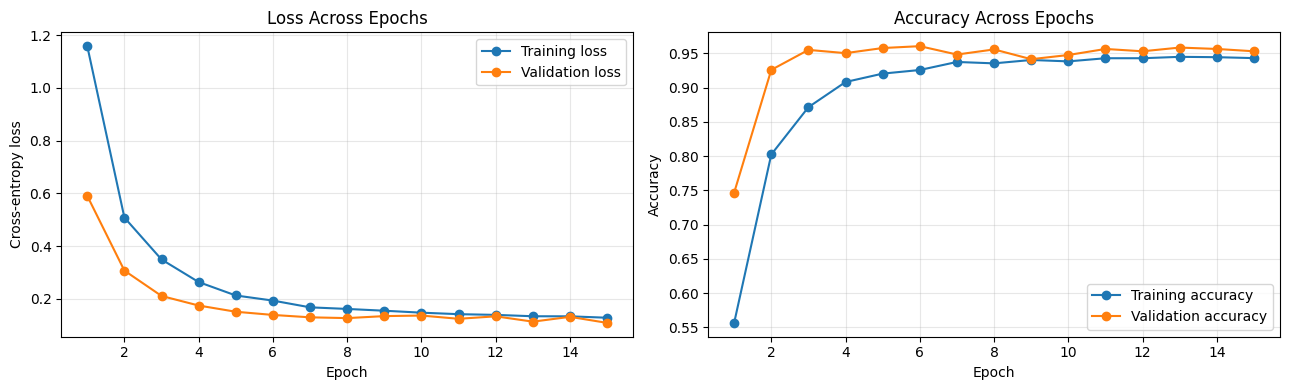

In [22]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    epochs_ran, history["train_loss"], marker="o",
    label="Training loss"
)
axes[0].plot(
    epochs_ran, history["val_loss"], marker="o",
    label="Validation loss"
)
axes[0].set_title("Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    epochs_ran, history["train_accuracy"], marker="o",
    label="Training accuracy"
)
axes[1].plot(
    epochs_ran, history["val_accuracy"], marker="o",
    label="Validation accuracy"
)
axes[1].set_title("Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Re-evaluate the restored best checkpoint.
final_val_loss, final_val_acc = run_evaluation(
    model, val_loader, criterion, device
)

print(f"Best checkpoint epoch: {best_epoch}")
print(f"Validation loss: {final_val_loss:.4f}")
print(f"Validation accuracy: {final_val_acc:.2%}")
print(f"Epochs completed: {len(history['train_loss'])}")

assert len(history["train_loss"]) > 0
assert np.isfinite(history["train_loss"]).all()
assert np.isfinite(history["val_loss"]).all()
assert 0 <= final_val_acc <= 1
assert best_state is not None

print("Phase 4 verification successful!")

Best checkpoint epoch: 15
Validation loss: 0.1091
Validation accuracy: 95.32%
Epochs completed: 15
Phase 4 verification successful!


In [24]:
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=128,
    shuffle=False
)

model.eval()

all_logits = []
all_true = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)

        logits = model(xb)

        all_logits.append(logits.cpu())
        all_true.append(yb.cpu())

all_logits = torch.cat(all_logits, dim=0)
y_true = torch.cat(all_true, dim=0).numpy()

# Predicted class = class with the highest logit.
y_pred = all_logits.argmax(dim=1).numpy()

assert len(y_pred) == len(y_test)
assert all_logits.shape == (len(y_test), 6)

print("Test samples:", len(y_true))
print("Prediction shape:", y_pred.shape)
print("Evaluation completed.")

Test samples: 2947
Prediction shape: (2947,)
Evaluation completed.


In [25]:
class_ids = list(range(6))

print(
    classification_report(
        y_true,
        y_pred,
        labels=class_ids,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    labels=class_ids,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred,
    labels=class_ids,
    average="weighted",
    zero_division=0
)

print(f"Test accuracy: {accuracy:.2%}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

                    precision    recall  f1-score   support

           WALKING     0.9836    0.9698    0.9766       496
  WALKING_UPSTAIRS     0.8929    0.9915    0.9396       471
WALKING_DOWNSTAIRS     0.9896    0.9095    0.9479       420
           SITTING     0.8361    0.7067    0.7660       491
          STANDING     0.7709    0.8665    0.8159       532
            LAYING     1.0000    0.9981    0.9991       537

          accuracy                         0.9074      2947
         macro avg     0.9122    0.9070    0.9075      2947
      weighted avg     0.9100    0.9074    0.9066      2947

Test accuracy: 90.74%
Macro F1-score: 0.9075
Weighted F1-score: 0.9066


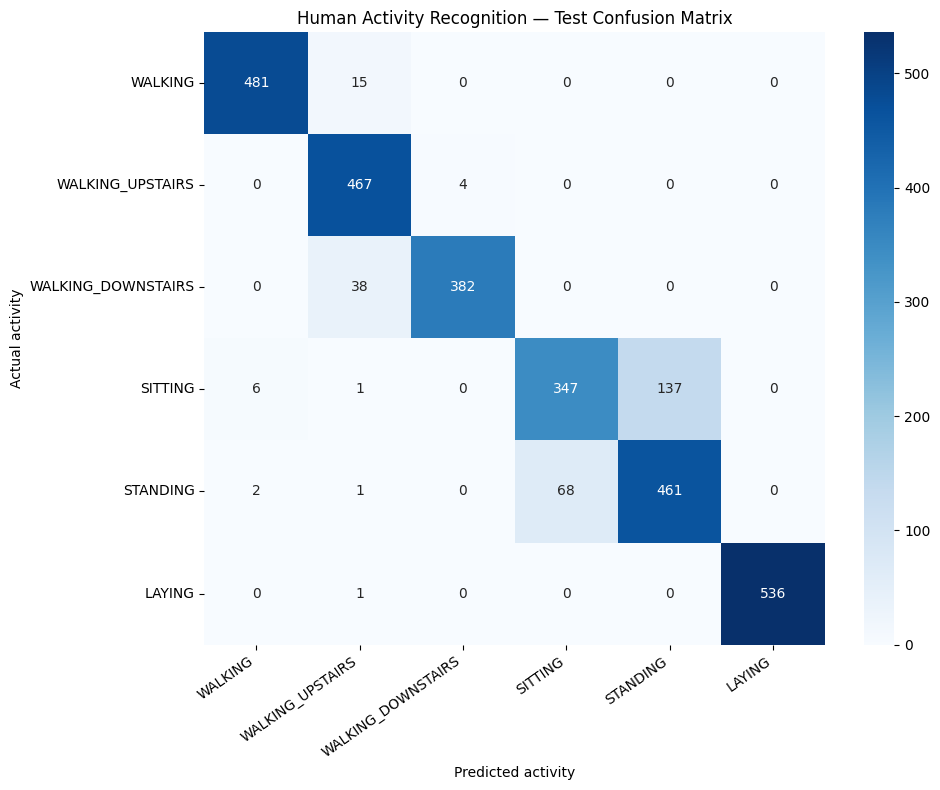

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true, y_pred,
    labels=class_ids
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Human Activity Recognition — Test Confusion Matrix")
plt.xlabel("Predicted activity")
plt.ylabel("Actual activity")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
probabilities = torch.softmax(all_logits, dim=1).numpy()

# Display a few examples, including correct and incorrect predictions.
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(y_true),
    size=min(10, len(y_true)),
    replace=False
)

results = pd.DataFrame({
    "Actual": [CLASS_NAMES[i] for i in y_true[sample_indices]],
    "Predicted": [CLASS_NAMES[i] for i in y_pred[sample_indices]],
    "Confidence": probabilities[
        sample_indices, y_pred[sample_indices]
    ],
    "Correct": y_true[sample_indices] == y_pred[sample_indices]
})

display(results.style.format({"Confidence": "{:.2%}"}))

,Actual,Predicted,Confidence,Correct
0,WALKING,WALKING,99.98%,True
1,SITTING,SITTING,78.68%,True
2,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS,99.89%,True
3,LAYING,LAYING,99.99%,True
4,WALKING,WALKING,96.11%,True
5,LAYING,LAYING,100.00%,True
6,STANDING,STANDING,91.94%,True
7,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS,99.98%,True
8,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS,82.45%,True
9,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS,100.00%,True


In [28]:
majority_class = int(np.bincount(y_fit.numpy()).argmax())

baseline_predictions = np.full(
    len(y_true),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_true, baseline_predictions
)

print("Baseline activity:", CLASS_NAMES[majority_class])
print(f"Baseline test accuracy: {baseline_accuracy:.2%}")
print(f"CNN test accuracy:      {accuracy:.2%}")
print(f"Absolute improvement:   {accuracy - baseline_accuracy:.2%}")

Baseline activity: LAYING
Baseline test accuracy: 18.22%
CNN test accuracy:      90.74%
Absolute improvement:   72.51%


In [29]:
from pathlib import Path
import json

OUTPUT_DIR = Path("/content/har_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

metrics = {
    "model": "1D CNN",
    "best_epoch": int(best_epoch),
    "test_accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "baseline_accuracy": float(baseline_accuracy)
}

with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

report = classification_report(
    y_true,
    y_pred,
    labels=class_ids,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(OUTPUT_DIR / "confusion_matrix.csv")

print("Saved:")
for file in OUTPUT_DIR.iterdir():
    print("-", file.name)

Saved:
- metrics.json
- classification_report.csv
- confusion_matrix.csv


In [30]:
%pip -q install -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 11.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [31]:
from google import genai
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

if not api_key:
    raise ValueError(
        "GEMINI_API_KEY is missing. Add it in Colab Secrets "
        "and enable notebook access."
    )

client = genai.Client(api_key=api_key)

# Use a currently documented model alias.
GEMINI_MODEL = "gemini-flash-latest"

print("Gemini client initialized.")
print("API key was loaded from Colab Secrets.")

Gemini client initialized.
API key was loaded from Colab Secrets.


In [36]:
import time
from google.genai.errors import APIError

for attempt in range(3):
    try:
        response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents="Reply with exactly: Gemini connection successful."
        )
        print(response.text)
        break
    except Exception as e:
        if "503" in str(e) and attempt < 2:
            print(f"Gemini is busy (503). Retrying in 3 seconds... (Attempt {attempt + 1}/3)")
            time.sleep(3)
        else:
            print("Could not connect to Gemini service due to high demand.")
            print("Error details:", e)
            break

Gemini is busy (503). Retrying in 3 seconds... (Attempt 1/3)
Gemini is busy (503). Retrying in 3 seconds... (Attempt 2/3)
Could not connect to Gemini service due to high demand.
Error details: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


In [37]:
def predict_activity(sensor_window):
    """
    sensor_window: NumPy array with shape (9, 128)
    """
    sensor_window = np.asarray(
        sensor_window, dtype=np.float32
    )

    if sensor_window.shape != (9, 128):
        raise ValueError(
            f"Expected shape (9, 128), got {sensor_window.shape}"
        )

    if not np.isfinite(sensor_window).all():
        raise ValueError("Input contains NaN or infinite values.")

    model.eval()

    x = torch.from_numpy(sensor_window).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    order = np.argsort(probs)[::-1]
    predicted_id = int(order[0])

    return {
        "predicted_activity": CLASS_NAMES[predicted_id],
        "predicted_class_id": predicted_id,
        "confidence": float(probs[predicted_id]),
        "second_best_activity": CLASS_NAMES[int(order[1])],
        "second_best_confidence": float(probs[order[1]]),
        "class_probabilities": {
            CLASS_NAMES[i]: float(probs[i])
            for i in range(len(CLASS_NAMES))
        }
    }

In [38]:
example_index = 0

prediction = predict_activity(X_test[example_index])

print("CNN prediction:")
for key, value in prediction.items():
    print(f"{key}: {value}")

print("\nActual activity:", CLASS_NAMES[y_test[example_index]])

assert prediction["predicted_activity"] in CLASS_NAMES
assert 0.0 <= prediction["confidence"] <= 1.0

assert abs(
    sum(prediction["class_probabilities"].values()) - 1.0
) < 1e-5

print("\nPrediction function verified.")

CNN prediction:
predicted_activity: STANDING
predicted_class_id: 4
confidence: 0.9730119109153748
second_best_activity: SITTING
second_best_confidence: 0.025229549035429955
class_probabilities: {'WALKING': 0.0016347109340131283, 'WALKING_UPSTAIRS': 0.0001238384866155684, 'WALKING_DOWNSTAIRS': 7.144931757352424e-09, 'SITTING': 0.025229549035429955, 'STANDING': 0.9730119109153748, 'LAYING': 1.863164023063746e-08}

Actual activity: STANDING

Prediction function verified.


In [39]:
import json

def explain_prediction_with_gemini(
    prediction,
    actual_activity=None,
    metrics=None
):
    evidence = {
        "cnn_prediction": prediction,
        "actual_activity": actual_activity,
        "evaluation_metrics": metrics or {}
    }

    prompt = f"""
You are an AI/ML explanation assistant for an educational
Human Activity Recognition project.

Explain the following evidence from a trained 1D CNN.
Do not make a new activity prediction.

Rules:
1. Treat the supplied CNN output as the model's prediction.
2. Explain confidence as the model's estimated probability,
   not as a guarantee of correctness.
3. If the actual activity is supplied, say whether the CNN
   prediction was correct.
4. You may suggest plausible reasons for an error, but label
   them as hypotheses, not proven causes.
5. Do not invent sensor measurements, feature importance,
   or evaluation metrics.
6. State that this is an educational model, not a medical
   or safety-critical system.

Respond with these headings:
- Prediction summary
- Confidence interpretation
- Correctness check
- Possible limitations
- Next debugging step

Evidence:
{json.dumps(evidence, indent=2)}
"""

    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt
    )

    if not response.text:
        raise RuntimeError("Gemini returned an empty response.")

    return response.text

In [41]:
example_index = 0

prediction = predict_activity(X_test[example_index])

actual_activity = CLASS_NAMES[
    int(y_test[example_index])
]

metrics = {
    "test_accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1)
}

try:
    explanation = explain_prediction_with_gemini(
        prediction=prediction,
        actual_activity=actual_activity,
        metrics=metrics
    )
    print(explanation)
except Exception as e:
    print("Could not retrieve Gemini explanation because the model is currently under high demand (503 Unavailable).")
    print("Fallback Summary of CNN Prediction:")
    print(f"- Predicted: {prediction['predicted_activity']} (Confidence: {prediction['confidence']:.2%})")
    print(f"- Actual: {actual_activity}")
    print(f"- Prediction was: {'Correct' if prediction['predicted_activity'] == actual_activity else 'Incorrect'}")

Could not retrieve Gemini explanation because the model is currently under high demand (503 Unavailable).
Fallback Summary of CNN Prediction:
- Predicted: STANDING (Confidence: 97.30%)
- Actual: STANDING
- Prediction was: Correct


In [43]:
import json
from pathlib import Path

OUTPUT_DIR = Path("/content/har_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

checkpoint_path = OUTPUT_DIR / "har_cnn.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": CLASS_NAMES,
        "input_channels": 9,
        "sequence_length": 128,
        "best_epoch": int(best_epoch)
    },
    checkpoint_path
)

with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Safely handle writing the explanation if the API call failed
final_explanation = globals().get("explanation", "")
if not final_explanation:
    final_explanation = (
        f"Could not retrieve Gemini explanation because the model was experiencing high demand.\n"
        f"Fallback Summary of CNN Prediction:\n"
        f"- Predicted: {prediction['predicted_activity']} (Confidence: {prediction['confidence']:.2%})\n"
        f"- Actual: {actual_activity}\n"
        f"- Prediction was: {'Correct' if prediction['predicted_activity'] == actual_activity else 'Incorrect'}\n"
    )

with open(OUTPUT_DIR / "gemini_explanation.txt", "w") as f:
    f.write(final_explanation)

print("Saved model:", checkpoint_path)
print("Saved metrics and fallback explanation.")

Saved model: /content/har_outputs/har_cnn.pth
Saved metrics and fallback explanation.


In [44]:
%pip -q install -U gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 1.2 MB/s eta 0:00:00


In [45]:
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np

def run_har_demo(sample_index, explain_with_gemini):
    idx = int(sample_index)

    # Obtain prediction from the trained CNN.
    result = predict_activity(X_test[idx])

    actual = CLASS_NAMES[int(y_test[idx])]
    predicted = result["predicted_activity"]

    # Display class probabilities.
    probability_data = {
        name: round(prob, 4)
        for name, prob in result["class_probabilities"].items()
    }

    # Plot the selected sample's body acceleration.
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(X_test[idx, 0, :], label="X-axis")
    ax.plot(X_test[idx, 1, :], label="Y-axis")
    ax.plot(X_test[idx, 2, :], label="Z-axis")
    ax.set_title(f"Body acceleration — test sample {idx}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Normalized acceleration")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()

    summary = (
        f"Actual activity: {actual}\n"
        f"Predicted activity: {predicted}\n"
        f"Model confidence: {result['confidence']:.2%}\n"
        f"Correct prediction: {actual == predicted}"
    )

    explanation_text = "Gemini explanation not requested."

    if explain_with_gemini:
        try:
            explanation_text = explain_prediction_with_gemini(
                prediction=result,
                actual_activity=actual,
                metrics=metrics
            )
        except Exception:
            explanation_text = (
                "Gemini explanation failed. Check your API key, "
                "model availability, quota, and connection. "
                "The CNN prediction is still available above."
            )

    return probability_data, summary, fig, explanation_text


demo = gr.Interface(
    fn=run_har_demo,
    inputs=[
        gr.Dropdown(
            choices=[str(i) for i in range(len(X_test))],
            value="0",
            label="Select a test sample"
        ),
        gr.Checkbox(
            value=False,
            label="Generate Gemini explanation (uses API quota)"
        )
    ],
    outputs=[
        gr.Label(num_top_classes=6, label="CNN activity probabilities"),
        gr.Textbox(label="Prediction summary", lines=4),
        gr.Plot(label="Sensor signal"),
        gr.Textbox(label="Gemini explanation", lines=10)
    ],
    title="Human Activity Recognition",
    description=(
        "Explore predictions from a trained 1D CNN using "
        "held-out smartphone sensor data."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b706b24ec3d0ada181.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [46]:
from pathlib import Path
import json

OUTPUT_DIR = Path("/content/har_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

readme = f"""
# Human Activity Recognition Using Deep Learning

## Overview

A Human Activity Recognition system that classifies six
activities from smartphone accelerometer and gyroscope data
using a 1D Convolutional Neural Network (CNN).

An optional Gemini API integration explains model outputs
using the prediction and evaluation evidence supplied to it.

## Activities

- Walking
- Walking upstairs
- Walking downstairs
- Sitting
- Standing
- Laying down

## Tech Stack

- Python
- Google Colab
- NumPy and Pandas
- PyTorch
- Scikit-learn
- Matplotlib and Seaborn
- Gradio
- Google Gemini API

## Dataset

UCI Human Activity Recognition Using Smartphones Dataset

https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

The input consists of nine inertial-sensor channels and
128 time steps per window.

## Architecture

1. Load and validate the sensor windows.
2. Apply a 1D CNN with convolution, ReLU, and max pooling.
3. Aggregate learned features using global average pooling.
4. Classify each window into six activity classes.
5. Evaluate predictions using classification metrics.
6. Optionally explain results using the Gemini API.

## Evaluation

- Test accuracy: {accuracy:.2%}
- Macro F1-score: {macro_f1:.4f}
- Weighted F1-score: {weighted_f1:.4f}
- Majority-class baseline accuracy: {baseline_accuracy:.2%}

These metrics describe the current trained checkpoint.
Recalculate them if the model or evaluation pipeline changes.

## How to Run

1. Open the notebook in Google Colab.
2. Run the cells in order.
3. Add GEMINI_API_KEY through Colab Secrets to enable
   the optional explanation feature.
4. Train or load the CNN checkpoint.
5. Launch the Gradio demo.

## Limitations

- This is an educational prototype.
- The demo uses pre-recorded dataset windows, not live phone sensors.
- Softmax confidence is not necessarily calibrated confidence.
- Gemini explanations are generated text, not proof of
  why the CNN made a prediction.
- Performance on new users may differ from test results.

## Future Improvements

- Compare the CNN with Random Forest and other baselines.
- Evaluate confidence calibration and error cases.
- Test robustness across participants and sensor conditions.
- Add live sensor collection in a separate application.

## Reproducibility

Document the selected participant split, random seeds,
training configuration, and evaluation metrics when
reproducing experiments.
"""

readme_path = OUTPUT_DIR / "README.md"
readme_path.write_text(readme.strip() + "\n", encoding="utf-8")

print("README created:", readme_path)
print(readme)

README created: /content/har_outputs/README.md

# Human Activity Recognition Using Deep Learning

## Overview

A Human Activity Recognition system that classifies six
activities from smartphone accelerometer and gyroscope data
using a 1D Convolutional Neural Network (CNN).

An optional Gemini API integration explains model outputs
using the prediction and evaluation evidence supplied to it.

## Activities

- Walking
- Walking upstairs
- Walking downstairs
- Sitting
- Standing
- Laying down

## Tech Stack

- Python
- Google Colab
- NumPy and Pandas
- PyTorch
- Scikit-learn
- Matplotlib and Seaborn
- Gradio
- Google Gemini API

## Dataset

UCI Human Activity Recognition Using Smartphones Dataset

https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

The input consists of nine inertial-sensor channels and
128 time steps per window.

## Architecture

1. Load and validate the sensor windows.
2. Apply a 1D CNN with convolution, ReLU, and max pooling.
3. Aggreg

In [47]:
import shutil
from pathlib import Path

OUTPUT_DIR = Path("/content/har_outputs")

# Ensure the model checkpoint exists before packaging.
assert (OUTPUT_DIR / "har_cnn.pth").exists(), (
    "Model checkpoint missing. Run the save-checkpoint cell first."
)

assert (OUTPUT_DIR / "README.md").exists(), (
    "README missing. Run the README generation cell first."
)

zip_path = shutil.make_archive(
    "/content/human_activity_recognition",
    "zip",
    root_dir=OUTPUT_DIR
)

print("Project package created:", zip_path)
print("Included files:")

for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Project package created: /content/human_activity_recognition.zip
Included files:
- README.md
- classification_report.csv
- confusion_matrix.csv
- gemini_explanation.txt
- har_cnn.pth
- metrics.json


In [48]:
from google.colab import files

files.download("/content/human_activity_recognition.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>